# Neural networks

In dit notebook gaan we neural networks toepassen op de Aria dataset.

het eerste deel van dit notebook is een kopie van de random forest van vorige sessie. Zo hoeven we de data voorbereiding niet opnieuw te doen.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import OrdinalEncoder

import tensorflow as tf
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("aria_users.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 623 entries, 0 to 622
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   user_id              623 non-null    int64  
 1   age                  599 non-null    float64
 2   country              623 non-null    str    
 3   region               623 non-null    str    
 4   education_level      623 non-null    str    
 5   device_type          623 non-null    str    
 6   subscription_type    623 non-null    str    
 7   signup_date          623 non-null    str    
 8   primary_use_case     623 non-null    str    
 9   daily_usage_minutes  623 non-null    float64
 10  sessions_per_week    623 non-null    int64  
 11  monthly_spend_eur    623 non-null    float64
 12  trust_in_ai          592 non-null    float64
 13  satisfaction_score   586 non-null    float64
 14  nps_score            623 non-null    int64  
 15  churned              623 non-null    str    
dtypes

In [3]:
# --------------------------------------------------
# 1. Remove duplicate rows and duplicate user IDs
# --------------------------------------------------
df = df.drop_duplicates()
df = df.drop_duplicates(subset="user_id", keep="first")

# --------------------------------------------------
# 2. Clean column names and text values
# --------------------------------------------------
df.columns = df.columns.str.strip().str.lower()

text_cols = df.select_dtypes(include=["object", "string"]).columns

for col in text_cols:
    df[col] = df[col].astype("string").str.strip()
    df[col] = df[col].replace(
        {"": pd.NA, "nan": pd.NA, "None": pd.NA, "NA": pd.NA}
    )

# --------------------------------------------------
# 3. Convert data types
# --------------------------------------------------
df["signup_date"] = pd.to_datetime(df["signup_date"], errors="coerce")

# Convert numeric columns to numeric, coercing invalid values to NaN
numeric_cols = [
    "user_id",
    "age",
    "daily_usage_minutes",
    "sessions_per_week",
    "monthly_spend_eur",
    "trust_in_ai",
    "satisfaction_score",
    "nps_score",
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# --------------------------------------------------
# 4. Clean invalid values
# --------------------------------------------------
# Treat implausible ages as missing
df.loc[~df["age"].between(13, 100), "age"] = np.nan

# Usage and spending cannot be negative
for col in ["daily_usage_minutes", "sessions_per_week", "monthly_spend_eur"]:
    df.loc[df[col] < 0, col] = np.nan

# Validate rating scales
df.loc[~df["trust_in_ai"].between(0, 10), "trust_in_ai"] = np.nan
df.loc[~df["satisfaction_score"].between(1, 5), "satisfaction_score"] = np.nan

# Normalize churn labels
df["churned"] = df["churned"].str.lower().map({
    "yes": 1,
    "no": 0,
    "true": 1,
    "false": 0,
    "1": 1,
    "0": 0,
})

# --------------------------------------------------
# 5. Encode text columns as numeric representations
# --------------------------------------------------
# Binary target: churned (0 = No, 1 = Yes)
# One-hot encoding: nominal categories with no natural order
nominal_cols = [
    "country",
    "region",
    "device_type",
    "subscription_type",
    "primary_use_case",
]

df = pd.get_dummies(
    df,
    columns=nominal_cols,
    dummy_na=True,
    dtype=int,
)

# Ordinal encoding: education has a natural order
education_order = [[
    "High School",
    "Bachelor",
    "Master",
    "PhD",
]]

education_encoder = OrdinalEncoder(
    categories=education_order,
    handle_unknown="use_encoded_value",
    unknown_value=np.nan,
    encoded_missing_value=np.nan,
)

df["education_level"] = education_encoder.fit_transform(
    df[["education_level"]]
).ravel()

# --------------------------------------------------
# 6. Convert signup date into numeric features
# --------------------------------------------------
df["signup_year"] = df["signup_date"].dt.year
df["signup_month"] = df["signup_date"].dt.month
df["signup_day"] = df["signup_date"].dt.day
df["signup_day_of_week"] = df["signup_date"].dt.dayofweek

# Days since signup, measured relative to the latest date in the dataset
latest_signup = df["signup_date"].max()
df["days_since_signup"] = (
    latest_signup - df["signup_date"]
).dt.days

df = df.drop(columns=["signup_date"])

# --------------------------------------------------
# 7. Impute missing values
# --------------------------------------------------
# Numeric columns: median imputation
# Missingness indicators preserve information about missing values
for col in df.columns:
    if df[col].isna().any():
        df[f"{col}_was_missing"] = df[col].isna().astype(int)

        if pd.api.types.is_numeric_dtype(df[col]):
            median_value = df[col].median()
            df[col] = df[col].fillna(
                median_value if pd.notna(median_value) else 0
            )

# --------------------------------------------------
# 8. Ensure all columns are numeric
# --------------------------------------------------
# Any remaining non-numeric columns are one-hot encoded
remaining_text_cols = df.select_dtypes(
    include=["object", "string", "category", "bool"]
).columns.tolist()

if remaining_text_cols:
    df = pd.get_dummies(
        df,
        columns=remaining_text_cols,
        dummy_na=True,
        dtype=int,
    )

# Final validation
assert df.select_dtypes(exclude=["number"]).empty, (
    "Some columns are still non-numeric."
)
assert not df.isna().any().any(), "Missing values remain."

print("Cleaned dataset shape:", df.shape)
print("Remaining missing values:", int(df.isna().sum().sum()))
print("Non-numeric columns:", df.select_dtypes(exclude=["number"]).columns.tolist())

df.head()

Cleaned dataset shape: (620, 56)
Remaining missing values: 0
Non-numeric columns: []


,user_id,age,education_level,daily_usage_minutes,sessions_per_week,monthly_spend_eur,trust_in_ai,satisfaction_score,nps_score,churned,...,primary_use_case_<NA>,signup_year,signup_month,signup_day,signup_day_of_week,days_since_signup,age_was_missing,daily_usage_minutes_was_missing,trust_in_ai_was_missing,satisfaction_score_was_missing
0,1001,37.0,2.0,2.5,0.0,0.26,6.3,4.0,6,0,...,0,2024,8,18,6,388,0,0,1,0
1,1002,23.0,1.0,21.2,3.0,0.06,9.0,2.0,39,0,...,0,2025,8,29,4,12,0,0,0,0
2,1003,42.0,3.0,9.0,3.0,0.17,8.9,2.0,46,0,...,0,2025,8,16,5,25,0,0,0,0
3,1004,44.0,1.0,23.8,2.0,9.90,6.1,3.0,45,0,...,0,2025,5,2,4,131,0,0,0,1
4,1005,16.0,1.0,16.0,1.0,0.03,5.9,3.0,-4,0,...,0,2025,9,6,5,4,0,0,0,1


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 620 entries, 0 to 619
Data columns (total 56 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   user_id                              620 non-null    int64  
 1   age                                  620 non-null    float64
 2   education_level                      620 non-null    float64
 3   daily_usage_minutes                  620 non-null    float64
 4   sessions_per_week                    620 non-null    float64
 5   monthly_spend_eur                    620 non-null    float64
 6   trust_in_ai                          620 non-null    float64
 7   satisfaction_score                   620 non-null    float64
 8   nps_score                            620 non-null    int64  
 9   churned                              620 non-null    int64  
 10  country_Belgium                      620 non-null    int64  
 11  country_France                       620 no

# Post data-prep
Hier begint de nieuwe code. Eerst gaan we een nieuwe variabele verzinnen die we willen gaan voorspellen. Dit is niet noodzakelijk, maar het is goed om een keer gezien te hebben hoe we met meerdere output neuronen een categoriale variabele kunnen voorspellen.

In [5]:
x = df.loc[:, df.columns != 'daily_usage_minutes']
y = df["daily_usage_minutes"] 

print(x.shape)
y.shape

(620, 55)


(620,)

In [6]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

X_train.shape

(496, 55)

In [ ]:
model = tf.keras.models.Sequential([
  tf.keras.layers.Dense(64, activation='relu'),
  tf.keras.layers.Dense(64, activation='relu'),
  tf.keras.layers.Dense(64, activation='relu'),
  tf.keras.layers.Dense(32, activation='relu'),
  tf.keras.layers.Dense(16, activation='relu'),
  tf.keras.layers.Dense(1)
])

In [15]:
model.compile(optimizer='adam',
              loss='mse',
              metrics=['mae'])

In [16]:
model.fit(X_train, y_train, epochs=50)


Epoch 1/50


16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 5005.9883 - mae: 57.6900     
Epoch 2/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1252.3906 - mae: 26.7525 
Epoch 3/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 766.1926 - mae: 19.0765 
Epoch 4/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 574.1396 - mae: 14.3546 
Epoch 5/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 528.6598 - mae: 13.7335 
Epoch 6/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 518.5618 - mae: 13.1780  
Epoch 7/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 484.2273 - mae: 12.5986
Epoch 8/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 476.2541 - mae: 12.3696 
Epoch 9/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 466.7994 - mae: 12.2491 
Epoch 10/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 478.9811 - mae: 12.6209 
Epoch 11/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 472.4436 - mae: 12.7780  
Epoch 12/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 471.7380 - mae: 11.9605 
Epoch

In [17]:
model.evaluate(X_test,  y_test, verbose=2)


4/4 - 0s - 25ms/step - loss: 377.4502 - mae: 11.3262


[377.4502258300781, 11.326207160949707]

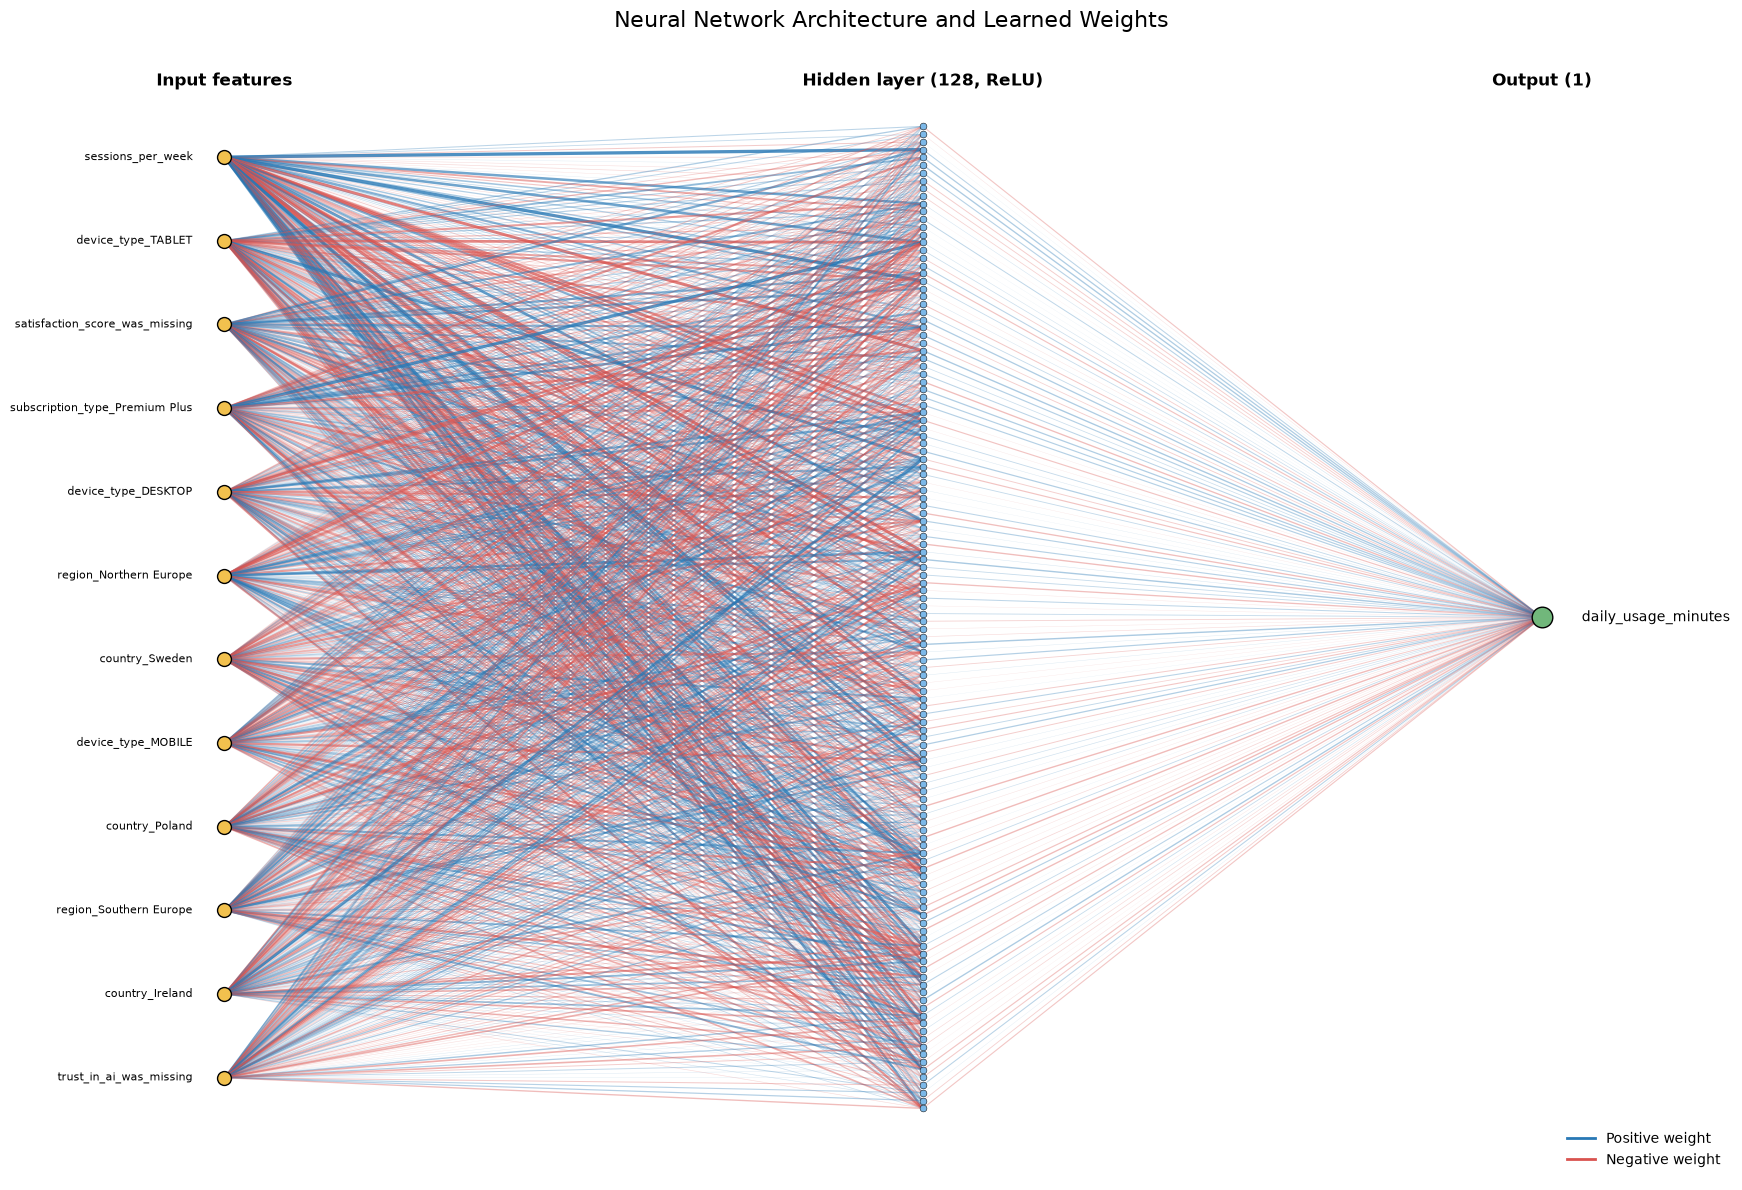

In [18]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Extract learned weights from the trained Keras model
W1, b1 = model.layers[0].get_weights()
W2, b2 = model.layers[1].get_weights()

# Select the 12 input features with the largest weight norms
n_features_to_show = min(12, W1.shape[0])

feature_strength = np.linalg.norm(W1, axis=1)
top_features = np.argsort(feature_strength)[-n_features_to_show:][::-1]

W1_selected = W1[top_features, :]
feature_names = np.asarray(X_train.columns)[top_features]

n_inputs = len(top_features)
n_hidden = W1.shape[1]

# Set up node positions
input_y = np.linspace(0.95, 0.05, n_inputs)
hidden_y = np.linspace(0.98, 0.02, n_hidden)

input_x = 0.08
hidden_x = 0.52
output_x = 0.91
output_y = 0.5

fig, ax = plt.subplots(figsize=(18, 12))
ax.set_xlim(-0.03, 1.03)
ax.set_ylim(-0.05, 1.05)
ax.axis("off")

# Normalize edge thickness across the displayed connections
all_weights = np.concatenate([
    W1_selected.ravel(),
    W2.ravel()
])
max_abs_weight = max(np.max(np.abs(all_weights)), 1e-12)

def draw_edge(x1, y1, x2, y2, weight):
    color = "#2878B5" if weight >= 0 else "#D9534F"
    width = 0.15 + 2.2 * abs(weight) / max_abs_weight
    alpha = 0.12 + 0.70 * abs(weight) / max_abs_weight

    ax.plot(
        [x1, x2], [y1, y2],
        color=color,
        linewidth=width,
        alpha=alpha,
        zorder=1
    )

# Input -> hidden connections
for i, yi in enumerate(input_y):
    for j, yj in enumerate(hidden_y):
        draw_edge(input_x, yi, hidden_x, yj, W1_selected[i, j])

# Hidden -> output connections
for j, yj in enumerate(hidden_y):
    draw_edge(hidden_x, yj, output_x, output_y, W2[j, 0])

# Draw nodes on top of the connections
ax.scatter(
    np.full(n_inputs, input_x), input_y,
    s=100, color="#F2C14E", edgecolors="black", zorder=3
)
ax.scatter(
    np.full(n_hidden, hidden_x), hidden_y,
    s=24, color="#7CB8E8", edgecolors="black",
    linewidths=0.35, zorder=3
)
ax.scatter(
    [output_x], [output_y],
    s=220, color="#71B77B", edgecolors="black", zorder=3
)

# Label input and output neurons
for name, yi in zip(feature_names, input_y):
    ax.text(input_x - 0.02, yi, str(name),
            ha="right", va="center", fontsize=8)

ax.text(output_x + 0.025, output_y,
        "daily_usage_minutes",
        ha="left", va="center", fontsize=10)

# Layer labels
ax.text(input_x, 1.02, "Input features",
        ha="center", fontsize=12, fontweight="bold")
ax.text(hidden_x, 1.02, "Hidden layer (128, ReLU)",
        ha="center", fontsize=12, fontweight="bold")
ax.text(output_x, 1.02, "Output (1)",
        ha="center", fontsize=12, fontweight="bold")

legend = [
    Line2D([0], [0], color="#2878B5", lw=2,
           label="Positive weight"),
    Line2D([0], [0], color="#D9534F", lw=2,
           label="Negative weight")
]
ax.legend(handles=legend, loc="lower right", frameon=False)

ax.set_title(
    "Neural Network Architecture and Learned Weights",
    fontsize=16, pad=20
)

plt.tight_layout()
plt.show()
